In [ ]:
from pathlib import Path
import pandas as pd

metric = "balanced_accuracy"  # "balanced_accuracy", "f1"
modes = ["bare", "ifc", "projection", "combined", "mlp_standardized", "mlp_raw"]

df = pd.read_csv(Path("../results") / "tabular.csv")


def mean_std(values, index, digits=3):
    stats = df.pivot_table(index=index, columns="mode", values=values, aggfunc=["mean", "std"])
    text = stats.map(f"{{:.{digits}f}}".format)  # std is nan when a cell has a single run
    return (text["mean"] + " ± " + text["std"])[modes].replace("nan ± nan", "")


## Mean ± std over seeds, per dataset and mode.

In [56]:
table = df.pivot_table(index="dataset", columns="mode", values=metric)[modes]
mean_std(metric, "dataset")

mode,bare,ifc,projection,combined
dataset,,,,
adult,0.776 ± 0.008,0.776 ± 0.005,0.770 ± 0.008,0.771 ± 0.005
arcene,0.778 ± 0.063,0.779 ± 0.059,0.758 ± 0.081,0.767 ± 0.061
bank_marketing,0.684 ± 0.023,0.716 ± 0.010,0.686 ± 0.013,0.680 ± 0.003
imdb,0.829 ± 0.015,0.827 ± 0.011,0.827 ± 0.008,0.823 ± 0.005
kick,0.615 ± 0.003,0.616 ± 0.003,0.616 ± 0.003,0.616 ± 0.003
letter,0.964 ± 0.003,0.966 ± 0.003,0.961 ± 0.003,0.961 ± 0.003
madelon,0.709 ± 0.005,0.715 ± 0.009,0.706 ± 0.015,0.714 ± 0.016
mnist,0.941 ± 0.002,0.942 ± 0.006,0.942 ± 0.005,0.939 ± 0.004
musk_v2,0.985 ± 0.009,0.986 ± 0.008,0.983 ± 0.012,0.985 ± 0.011


## Difference from bare (positive = the addition helps).

In [57]:
diff = table.drop(columns="bare").sub(table["bare"], axis=0).round(4)
diff

mode,ifc,projection,combined
dataset,,,
adult,0.0004,-0.0062,-0.0047
arcene,0.0009,-0.0204,-0.0106
bank_marketing,0.0319,0.0017,-0.0047
imdb,-0.0018,-0.0020,-0.0062
kick,0.0004,0.0007,0.0011
letter,0.0020,-0.0033,-0.0034
madelon,0.0056,-0.0031,0.0044
mnist,0.0003,0.0008,-0.0019
musk_v2,0.0007,-0.0027,-0.0007


## average gain and win/tie/loss counts over datasets.

In [58]:
pd.DataFrame({
    "mean_diff": diff.mean(),
    "std_diff": diff.std(),
    "wins": (diff > 0).sum(),
    "ties": (diff == 0).sum(),
    "losses": (diff < 0).sum(),
}).round(4)

,mean_diff,std_diff,wins,ties,losses
mode,,,,,
ifc,0.0029,0.0083,9,2,4
projection,-0.0095,0.0241,5,1,9
combined,-0.0084,0.0228,4,0,11


## Average rank (1 = best) 

In [64]:
print(table.rank(axis=1, ascending=False).mean().round(2))

mode
bare          2.27
ifc           1.77
projection    3.03
combined      2.93
dtype: float64


## mean and std of training time, inference time and  depth 

In [60]:
df.groupby("mode")[["fit_seconds", "predict_seconds", "n_layers"]].agg(["mean", "std"]).round(2)

fit_seconds        predict_seconds       n_layers      
                  mean    std            mean   std     mean   std
mode                                                              
bare             20.55  24.89            0.22  0.38     2.57  1.76
combined         34.17  38.77            0.22  0.34     2.69  1.97
ifc              24.42  28.30            0.24  0.40     2.71  1.81
projection       34.89  48.08            0.27  0.48     2.75  1.83

## number of layers

In [70]:
display(pd.crosstab(df["n_layers"], df["mode"])[modes])
# mean_std(metric, "n_layers")

mode,bare,ifc,projection,combined
n_layers,,,,
1,19,15,17,16
2,27,30,27,34
3,16,15,16,11
4,5,8,4,5
5,5,1,3,3
6,0,2,4,0
7,1,2,2,2
8,0,0,1,2
10,2,2,1,2


In [71]:
df["relative"] = df[metric] - df.groupby("dataset")[metric].transform("mean")
mean_std("relative", "n_layers", digits=4)

mode,bare,ifc,projection,combined
n_layers,,,,
1,0.0120 ± 0.0327,0.0209 ± 0.0324,-0.0194 ± 0.0221,-0.0174 ± 0.0213
2,-0.0016 ± 0.0165,0.0045 ± 0.0119,-0.0079 ± 0.0267,-0.0058 ± 0.0164
3,0.0044 ± 0.0220,0.0060 ± 0.0176,-0.0027 ± 0.0087,-0.0001 ± 0.0137
4,0.0020 ± 0.0077,0.0006 ± 0.0069,0.0048 ± 0.0088,0.0035 ± 0.0133
5,0.0015 ± 0.0105,-0.0748 ± nan,0.0328 ± 0.0528,0.0014 ± 0.0060
6,,0.0010 ± 0.0015,0.0047 ± 0.0033,
7,0.0005 ± nan,0.0105 ± 0.0012,0.0023 ± 0.0010,0.0048 ± 0.0000
8,,,0.0047 ± nan,0.0101 ± 0.0133
10,0.0042 ± 0.0071,0.0036 ± 0.0126,0.0103 ± nan,0.0374 ± 0.0588


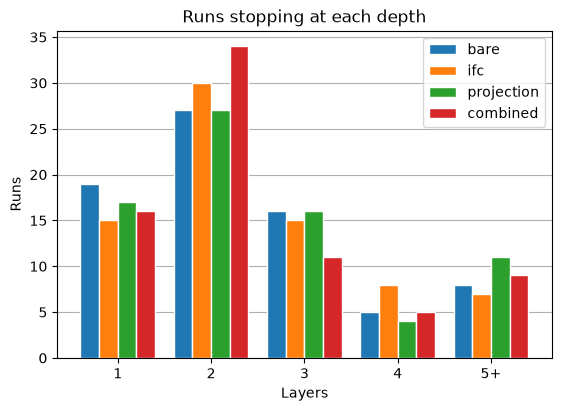

In [69]:
layers = df["n_layers"].clip(upper=5)
labels = ["1", "2", "3", "4", "5+"]

fig, ax = plt.subplots(figsize=(5.5, 4), layout="constrained")

counts = pd.crosstab(layers, df["mode"])[modes]
counts.plot.bar(ax=ax, width=0.8, edgecolor="white", rot=0)

ax.set_xticks(range(5), labels)
ax.set(title="Runs stopping at each depth", xlabel="Layers", ylabel="Runs")

ax.grid(axis="y")
ax.set_axisbelow(True)
plt.legend()
plt.show()